# Known Variable Stars in Public Rubin Alerts with LINCC Frameworks

## VSX → Gaia DR3 → Rubin Alert Archive

This corrected, self-contained notebook supports two science paths:

1. **Anomaly detection in public Rubin alerts**
2. **Distance preparation with RR Lyrae stars**

The notebook opens each remote catalog once, reuses all intermediate products in memory, and includes compatibility fixes for:

- Gaia access through HTTPS rather than S3 cloud options;
- LSDB crossmatch suffixes such as `OID_vsx`;
- `NestedFrame.to_parquet()` not accepting `index=False`;
- explicit selection and robust flattening of `prvDiaForcedSources`;
- Rubin time-series fields such as `midpointMjdTai`, `band`, `psfFlux`, and `psfFluxErr`.

> A VSX source, Gaia `source_id`, Rubin `diaSourceId`, and Rubin DIA object are different entities. An alert packet is not automatically a complete light curve or a unique astrophysical source.


In [1]:
!pip install nested_pandas
!pip install hats
!pip install lsdb
!pip install dask distributed

  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
Using cached fsspec-2026.9.0-py3-none-any.whl (221 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [nested_pandas]m 3/5 [universal_pathlib]
  Using cached aiohappyeyeballs-2.7.1-py3-none-any.whl.metadata (5.9 kB)
  Using cached aiosignal-1.4.0-py3-none-any.whl.metadata (3.7 kB)
  Using cached attrs-26.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached frozenlist-1.8.0-cp313-cp313-macosx_11_0_arm64.whl.metadata (20 kB)
  Using cached propcache-0.5.4-cp313-cp313-macosx_11_0_arm64.whl.metadata (25 kB)
  Using cached yarl-1.25.1-cp313-cp313-macosx_11_0_arm64.whl.metadata (111 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 545.8/545.8 kB 16.2 MB/s  0:00:00
Using cached yarl-1.25.1-cp313-cp313-macosx_11_0_arm64.whl (103 kB)
Using cached aiohappyeyeballs-2.7.1-py3-none-any.whl (15 kB)
Using cached aiosignal-1.4.0-py3-none-any.whl (7.5 kB)
Using cached attrs-26.1.0-py3-none-any.whl (67 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## 1. Environment and imports

Run with the **Python (LINCC Rubin)** kernel.


In [3]:
import os
import sys
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nested_pandas as npd
import lsdb
import hats

from astropy.timeseries import LombScargle
from dask.distributed import Client
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler

pd.set_option("display.max_columns", 100)
print("Python executable:", sys.executable)
print("Conda environment:", os.environ.get("CONDA_DEFAULT_ENV"))
print("Python:", sys.version.split()[0])
print("LSDB:", lsdb.__version__)
print("HATS:", hats.__version__)
print("nested-pandas:", npd.__version__)


Python executable: /Users/jzuluaga/dev/rubin-workshop/.venv/bin/python
Conda environment: None
Python: 3.13.3
LSDB: 0.11.0
HATS: 0.11.0
nested-pandas: 0.7.2


## 2. Start Dask

In [4]:
try:
    client.close()
except Exception:
    pass

client = Client(n_workers=2, threads_per_worker=1, memory_limit="2GB")
client


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 2
Total threads: 2,Total memory: 3.73 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:54929,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:54936,Total threads: 1
Dashboard: http://127.0.0.1:54938/status,Memory: 1.86 GiB
Nanny: tcp://127.0.0.1:54932,


## 3. Catalog paths and field configuration

Gaia is accessed through the official LSDB HTTPS mirror. This avoids an incompatibility in some LSDB/HATS/nested-pandas combinations where cloud-storage keyword arguments are forwarded incorrectly to PyArrow.


In [5]:
VSX_PATH = "https://data.lsdb.io/hats/vsx/"
GAIA_PATH = "https://data.lsdb.io/hats/gaia_dr3/gaia/"
ALERTS_PATH = "https://data.lsdb.io/hats/rubin_alert_archive"

FIELDS = {
    "ELAIS-S1": (9.45, -44.02),
    "XMM-LSS": (35.57, -4.82),
    "ECDFS": (52.98, -28.12),
    "COSMOS": (150.11, 2.23),
    "EDFS-a": (58.90, -49.32),
    "EDFS-b": (63.60, -47.60),
}

FIELD = "ECDFS"
RA0, DEC0 = FIELDS[FIELD]
RADIUS_ARCSEC = 3600.0
MATCH_RADIUS_ARCSEC = 1.0
cone = lsdb.ConeSearch(RA0, DEC0, radius_arcsec=RADIUS_ARCSEC)

print(FIELD, RA0, DEC0, RADIUS_ARCSEC)


ECDFS 52.98 -28.12 3600.0


## 4. Open metadata and regional catalogs once

In [6]:
vsx_meta = lsdb.open_catalog(VSX_PATH)
gaia_meta = lsdb.open_catalog(GAIA_PATH)
alerts_meta = lsdb.open_catalog(ALERTS_PATH)

print("VSX columns:", list(vsx_meta.columns))
print("Gaia column count:", len(gaia_meta.columns))
print("Alert columns:", list(alerts_meta.columns))


VSX columns: ['OID', 'Name', 'VarFlag', 'RAdeg', 'DEdeg', 'Type', 'LimitFlagOnMax', 'MagMax', 'MaxUncertaintyFlag', 'MaxPassband', 'MinIsAmplitude', 'LimitFlagOnMin', 'MagMin', 'MinUncertaintyFlag', 'MinPassband', 'Epoch', 'EpochUncertaintyFlag', 'LimitFlagOnPeriod', 'Period', 'PeriodUncertaintyFlag', 'SpectralType']
Gaia column count: 152
Alert columns: ['ra', 'dec', 'diaSourceId', 'diaSource', 'diaObject', 'prvDiaForcedSources']


In [8]:
VSX_REQUESTED = [
    "OID", "Name", "VarFlag", "RAdeg", "DEdeg", "Type",
    "MagMax", "MaxPassband", "MagMin", "MinPassband",
    "Epoch", "Period", "SpectralType",
]
GAIA_REQUESTED = [
    "source_id", "ref_epoch", "ra", "dec", "parallax", "parallax_error",
    "pmra", "pmra_error", "pmdec", "pmdec_error", "ruwe",
    "phot_g_mean_mag", "phot_bp_mean_mag", "phot_rp_mean_mag",
]
ALERT_REQUESTED = [
    "diaSourceId", "ra", "dec", "prvDiaSources", "prvDiaForcedSources",
]

vsx_columns = [x for x in VSX_REQUESTED if x in vsx_meta.columns]
gaia_columns = [x for x in GAIA_REQUESTED if x in gaia_meta.columns]
alert_columns = [x for x in ALERT_REQUESTED if x in alerts_meta.columns]

vsx = lsdb.open_catalog(VSX_PATH, columns=vsx_columns, search_filter=cone)
gaia = lsdb.open_catalog(GAIA_PATH, columns=gaia_columns, search_filter=cone)
alerts = lsdb.open_catalog(ALERTS_PATH, columns=alert_columns, search_filter=cone)

print("Selected VSX columns:", vsx_columns)
print("Selected Gaia columns:", gaia_columns)
print("Selected alert columns:", alert_columns)


Selected VSX columns: ['OID', 'Name', 'VarFlag', 'RAdeg', 'DEdeg', 'Type', 'MagMax', 'MaxPassband', 'MagMin', 'MinPassband', 'Epoch', 'Period', 'SpectralType']
Selected Gaia columns: ['source_id', 'ref_epoch', 'ra', 'dec', 'parallax', 'parallax_error', 'pmra', 'pmra_error', 'pmdec', 'pmdec_error', 'ruwe', 'phot_g_mean_mag', 'phot_bp_mean_mag', 'phot_rp_mean_mag']
Selected alert columns: ['diaSourceId', 'ra', 'dec', 'prvDiaForcedSources']


## 5. Verify remote reads before crossmatching

In [9]:
display(vsx.head(5))
display(gaia.head(5))
display(alerts.head(5))


Computing Catalog: 100%|██████████| 1/1 [00:07<00:00,  7.24s/it]


,OID,Name,VarFlag,RAdeg,DEdeg,Type,MagMax,MaxPassband,MagMin,MinPassband,Epoch,Period,SpectralType
_healpix_29,,,,,,,,,,,,,
2528478682352289901,2894689,Gaia DR3 5056957338272473856,0,52.30729,-28.90523,ROT,18.05,G,18.17,G,<NA>,<NA>,<NA>
2528480266157691388,2894334,Gaia DR3 5056960503664636160,0,52.24225,-28.87815,ROT,15.04,G,15.09,G,<NA>,<NA>,M
2528480869384769464,2894210,Gaia DR3 5056961736318632320,0,52.22042,-28.82928,ROT,18.6,G,18.72,G,<NA>,2.17289,<NA>
2528541259764327373,2898460,Gaia DR3 5057082515095431680,0,52.98212,-29.11467,ROT,15.79,G,15.83,G,<NA>,<NA>,M
2528542016517128281,2898983,Gaia DR3 5057084026923915136,0,53.06977,-29.069,ROT,16.57,G,16.61,G,<NA>,6.1236,K


Computing Catalog: 100%|██████████| 1/1 [00:21<00:00, 21.31s/it]


,source_id,ref_epoch,ra,dec,parallax,parallax_error,pmra,pmra_error,pmdec,pmdec_error,ruwe,phot_g_mean_mag,phot_bp_mean_mag,phot_rp_mean_mag
_healpix_29,,,,,,,,,,,,,,
2528478166644625470,5056956311777326080,2016.0,52.33913,-28.939012,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,21.24593,20.845291,19.347668
2528478682346998320,5056957338272473856,2016.0,52.307449,-28.90524,4.073346,0.122007,30.703969,0.08159,-2.835781,0.119537,1.036844,18.134504,19.843584,16.912119
2528478699685094287,5056957376927480832,2016.0,52.285389,-28.904382,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,21.004385,21.66342,19.728016
2528478711049714177,5056957406991951104,2016.0,52.300272,-28.896398,0.711557,0.49785,2.150347,0.322343,2.734157,0.474239,1.066774,20.124313,21.075653,19.023399
2528480199073001807,5056960396289189248,2016.0,52.262845,-28.892603,1.183779,0.131804,10.934982,0.087648,2.710204,0.134758,1.049687,18.313841,19.252707,17.357117


Computing Catalog: 100%|██████████| 1/1 [00:03<00:00,  3.68s/it]


diaSourceId         ra        dec  \
_healpix_29                                                     
2528478682345737910  170107646612865083  52.307548 -28.905226   
2528478711039586141  170019696016359497  52.300518 -28.896263   
2528480307713372758  170068069954617387  52.253476 -28.877491   
2528480307801498296  170019696016359614  52.253158 -28.877506   
2528480724471019502  170019696149004351  52.219962  -28.85544   

                                                   prvDiaForcedSources  
_healpix_29                                                             
2528478682345737910                                                 []  
2528478711039586141  [{diaForcedSourceId: 170019696016359467, diaOb...  
2528480307713372758                                                 []  
2528480307801498296                                                 []  
2528480724471019502                                                 []

## 6. Inspect VSX and select RR Lyrae

In [10]:
vsx_region = vsx.compute()
print(f"VSX sources in {FIELD}: {len(vsx_region):,}")
display(vsx_region.head(20))
display(vsx_region["Type"].value_counts(dropna=False).head(30))

RR_PATTERN = r"(^|[+/:])RR(?:AB|C|D|S)?(?:$|[+/:])"
rr_vsx = vsx_region[
    vsx_region["Type"].astype("string").str.upper().str.contains(
        RR_PATTERN, regex=True, na=False
    )
].copy()
rr_vsx["Period_numeric"] = pd.to_numeric(rr_vsx["Period"], errors="coerce")
print("RR Lyrae candidates:", len(rr_vsx))
display(rr_vsx[["OID", "Name", "Type", "Period", "RAdeg", "DEdeg"]].head(30))


Computing Catalog:   0%|          | 0/1 [00:00<?, ?it/s]

Computing Catalog: 100%|██████████| 1/1 [00:07<00:00,  7.00s/it]

VSX sources in ECDFS: 221


,OID,Name,VarFlag,RAdeg,DEdeg,Type,MagMax,MaxPassband,MagMin,MinPassband,Epoch,Period,SpectralType
_healpix_29,,,,,,,,,,,,,
2528478682352289901,2894689,Gaia DR3 5056957338272473856,0,52.30729,-28.90523,ROT,18.05,G,18.17,G,<NA>,<NA>,<NA>
2528480266157691388,2894334,Gaia DR3 5056960503664636160,0,52.24225,-28.87815,ROT,15.04,G,15.09,G,<NA>,<NA>,M
2528480869384769464,2894210,Gaia DR3 5056961736318632320,0,52.22042,-28.82928,ROT,18.6,G,18.72,G,<NA>,2.17289,<NA>
2528541259764327373,2898460,Gaia DR3 5057082515095431680,0,52.98212,-29.11467,ROT,15.79,G,15.83,G,<NA>,<NA>,M
2528542016517128281,2898983,Gaia DR3 5057084026923915136,0,53.06977,-29.069,ROT,16.57,G,16.61,G,<NA>,6.1236,K
2528549812539859628,2901160,Gaia DR3 5057099626245119744,0,53.45321,-28.97624,ROT,16.67,G,16.72,G,<NA>,<NA>,K
2528549886521250373,2901271,Gaia DR3 5057099763684071552,0,53.47497,-28.95,ROT,15.01,G,15.05,G,<NA>,<NA>,M
2528551502053415653,2900131,Gaia DR3 5057102993500173440,0,53.26437,-29.08733,ROT,18.17,G,18.3,G,<NA>,3.67438,<NA>
2528551591220243761,2900393,Gaia DR3 5057103165298179840,0,53.31346,-29.07597,ROT,14.65,G,14.7,G,<NA>,<NA>,M


Type
ROT                194
VAR                  7
RS                   5
RRAB                 2
E                    2
EW                   2
S                    2
E+ROT                1
DSCT|GDOR|SXPHE      1
SRB                  1
UGSU                 1
EB|EW                1
MISC                 1
SN Ia                1
Name: count, dtype: int64[pyarrow]

RR Lyrae candidates: 2


/var/folders/xn/75ncx53144919w099wx5x5mw0000gn/T/ipykernel_9927/1898343873.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  vsx_region["Type"].astype("string").str.upper().str.contains(


,OID,Name,Type,Period,RAdeg,DEdeg
_healpix_29,,,,,,
2528551671458092321,672397,PS1-3PI J033317.09-290331.4,RRAB,0.578005,53.32123,-29.05875
2540771540180594195,178937,GUVV-2 J033500.4-272854.8,RRAB,0.697574,53.75187,-27.48197


## 7. Helper functions for crossmatch-column normalization and safe Parquet output

In [11]:
def first_existing(columns, candidates, contains=None):
    columns = list(columns)
    for candidate in candidates:
        if candidate in columns:
            return candidate
    if contains is not None:
        matches = [c for c in columns if contains.lower() in str(c).lower()]
        if matches:
            return matches[0]
    return None


def safe_to_parquet(frame, filename):
    """Save either a pandas DataFrame or nested-pandas NestedFrame."""
    try:
        frame.to_parquet(filename, index=False)
    except TypeError as error:
        if "unexpected keyword argument 'index'" not in str(error):
            raise
        frame.to_parquet(filename)
    print(f"Saved: {filename}")


## 8. Crossmatch VSX with Gaia DR3

In [12]:
vsx_gaia_catalog = vsx.crossmatch(
    gaia,
    radius_arcsec=MATCH_RADIUS_ARCSEC,
    n_neighbors=2,
    how="left",
    suffixes=("_vsx", "_gaia"),
)
vsx_gaia = vsx_gaia_catalog.compute()
print(vsx_gaia.shape)
print(vsx_gaia.columns.tolist())
display(vsx_gaia.head())


/Users/jzuluaga/dev/rubin-workshop/.venv/lib/python3.13/site-packages/lsdb/catalog/catalog.py:410: FutureWarning: The default suffix behavior will change from applying suffixes to all columns to only applying suffixes to overlapping columns in a future release.To maintain the current behavior, explicitly set `suffix_method='all_columns'`. To change to the new behavior, set `suffix_method='overlapping_columns'`.
  warnings.warn(
/Users/jzuluaga/dev/rubin-workshop/.venv/lib/python3.13/site-packages/lsdb/operations/functions/crossmatch_catalog_data.py:357: RuntimeWarning: Right catalog does not have a margin cache. Results may be incomplete and/or inaccurate.
  warnings.warn(
Computing Catalog:   0%|          | 0/2 [00:00<?, ?it/s]2026-10-13 13:23:13,623 - distributed.worker - ERROR - Compute Failed
Key:       ('read_pixel-bc0e02c834392769d6e0879b36665941', 0)
State:     executing
Task:  <Task ('read_pixel-bc0e02c834392769d6e0879b36665941', 0) read_pixel(..., ...)>
Exception: 'TypeError("

TypeError: can't concat TimeoutError to bytes

### Normalize the crossmatch column names

LSDB may preserve `OID` or rename it to `OID_vsx`. This cell detects the actual names and converts them to stable names used in the rest of the notebook.


In [ ]:
VSX_OID_RAW = first_existing(vsx_gaia.columns, ["OID", "OID_vsx"], contains="OID")
GAIA_DIST_RAW = first_existing(
    vsx_gaia.columns,
    ["_dist_arcsec", "_dist_arcsec_gaia", "_dist_arcsec_vsx"],
    contains="dist_arcsec",
)

if VSX_OID_RAW is None or GAIA_DIST_RAW is None:
    raise KeyError(f"Could not identify OID or distance. Columns: {vsx_gaia.columns.tolist()}")

rename_roles = {
    VSX_OID_RAW: "vsx_oid",
    GAIA_DIST_RAW: "vsx_gaia_dist_arcsec",
}
for target, candidates in {
    "vsx_name": ["Name", "Name_vsx"],
    "vsx_type": ["Type", "Type_vsx"],
    "vsx_period": ["Period", "Period_vsx"],
    "gaia_source_id": ["source_id", "source_id_gaia"],
    "gaia_parallax": ["parallax", "parallax_gaia"],
    "gaia_parallax_error": ["parallax_error", "parallax_error_gaia"],
    "gaia_ruwe": ["ruwe", "ruwe_gaia"],
    "gaia_g_mag": ["phot_g_mean_mag", "phot_g_mean_mag_gaia"],
}.items():
    raw = first_existing(vsx_gaia.columns, candidates)
    if raw is not None:
        rename_roles[raw] = target

vsx_gaia_norm = vsx_gaia.rename(columns=rename_roles)
print("Renamed columns:", rename_roles)


Renamed columns: {'OID_vsx': 'vsx_oid', '_dist_arcsec': 'vsx_gaia_dist_arcsec', 'Name_vsx': 'vsx_name', 'Type_vsx': 'vsx_type', 'Period_vsx': 'vsx_period', 'source_id_gaia': 'gaia_source_id', 'parallax_gaia': 'gaia_parallax', 'parallax_error_gaia': 'gaia_parallax_error', 'ruwe_gaia': 'gaia_ruwe', 'phot_g_mean_mag_gaia': 'gaia_g_mag'}


In [ ]:
vsx_gaia_sorted = vsx_gaia_norm.sort_values(
    ["vsx_oid", "vsx_gaia_dist_arcsec"], na_position="last"
)
vsx_gaia_best = vsx_gaia_sorted.drop_duplicates("vsx_oid", keep="first").copy()
vsx_gaia_best["gaia_match_ok"] = (
    vsx_gaia_best["vsx_gaia_dist_arcsec"].notna()
    & vsx_gaia_best["vsx_gaia_dist_arcsec"].le(MATCH_RADIUS_ARCSEC)
)
print("VSX sources with Gaia match:", int(vsx_gaia_best["gaia_match_ok"].sum()))
display(vsx_gaia_best.head(20))

safe_to_parquet(vsx_gaia_best, "vsx_gaia_best.parquet")


VSX sources with Gaia match: 209


,vsx_oid,vsx_name,VarFlag_vsx,RAdeg_vsx,DEdeg_vsx,vsx_type,MagMax_vsx,MaxPassband_vsx,MagMin_vsx,MinPassband_vsx,Epoch_vsx,vsx_period,SpectralType_vsx,gaia_source_id,ref_epoch_gaia,ra_gaia,dec_gaia,gaia_parallax,gaia_parallax_error,pmra_gaia,pmra_error_gaia,pmdec_gaia,pmdec_error_gaia,gaia_ruwe,gaia_g_mag,phot_bp_mean_mag_gaia,phot_rp_mean_mag_gaia,vsx_gaia_dist_arcsec,gaia_match_ok
_healpix_29,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2528682355446329688,14226,T For,0,52.39408,-28.40294,SRB,9.49,V,1.16,V,2452005.8,91.8,M2,5057364711626765056,2016.0,52.394141,-28.40295,0.418993,0.015898,13.979033,0.01096,-0.013055,0.015689,1.169857,9.190667,10.233297,8.182524,0.196017,True
2528711101883270239,178931,GUVV-2 J033339.3-281723.6,0,53.41375,-28.28989,VAR,19.65,NUV,0.81,NUV,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,False
2540771540180594195,178937,GUVV-2 J033500.4-272854.8,0,53.75187,-27.48197,RRAB,14.68,CV,0.83,CV,2454449.47,0.697574,<NA>,5081543075400797312,2016.0,53.751899,-27.481987,0.14181,0.019826,4.858624,0.012791,-6.86489,0.019779,1.11785,14.553511,14.774092,14.180634,0.110982,True
2528754196536432438,250177,CD-28 1189,0,53.38204,-27.88608,VAR,8.8,V,<NA>,<NA>,<NA>,<NA>,K5,5057508369692660352,2016.0,53.382036,-27.886093,0.596737,0.016494,1.222216,0.010128,-1.029159,0.015323,1.028934,8.795432,9.773361,7.823918,0.04744,True
2528704549707550133,252837,SSS 110224:033350-282244,0,53.45736,-28.37869,UGSU,14.4,V,18.6,CV,<NA>,<NA>,<NA>,5057409070048839040,2016.0,53.457405,-28.378704,1.507151,0.051895,-6.238699,0.052296,-1.250677,0.051582,1.020434,18.052298,18.25979,17.635105,0.152779,True
2530238980791518545,480336,SSS_J032827.8-273339,0,52.11597,-27.56111,EW,15.17,CV,0.39,CV,<NA>,0.251507,<NA>,5060477944441509504,2016.0,52.116157,-27.561096,1.205837,0.024846,38.242362,0.016326,3.302967,0.022224,1.013287,15.1542,15.594949,14.537277,0.598897,True
2528731767026968303,480386,SSS_J033507.0-275443,0,53.77834,-27.9128,MISC,14.52,CV,0.2,CV,<NA>,0.333047,<NA>,5057463530234126208,2016.0,53.778412,-27.912769,1.14948,0.031177,13.727242,0.020758,4.924174,0.031053,1.719488,14.486292,14.947598,13.844088,0.253997,True
2528726319458660734,480394,SSS_J033551.6-275418,0,53.96432,-27.90579,EB|EW,15.2,CV,0.56,CV,<NA>,0.572112,<NA>,5057452638197057792,2016.0,53.964341,-27.905794,0.303141,0.025681,6.749257,0.01706,-4.232418,0.025794,0.995098,15.081479,15.272805,14.749591,0.068575,True
2528691262385487240,555914,ASASSN-V J033147.60-281307.9,0,52.94833,-28.21887,EW,13.88,V,14.25,V,2456849.907,0.378966,<NA>,5057382509971250176,2016.0,52.948351,-28.21887,0.661791,0.01561,1.510525,0.010339,2.525702,0.016129,1.000478,13.999614,14.205035,13.63763,0.06679,True


Saved: vsx_gaia_best.parquet


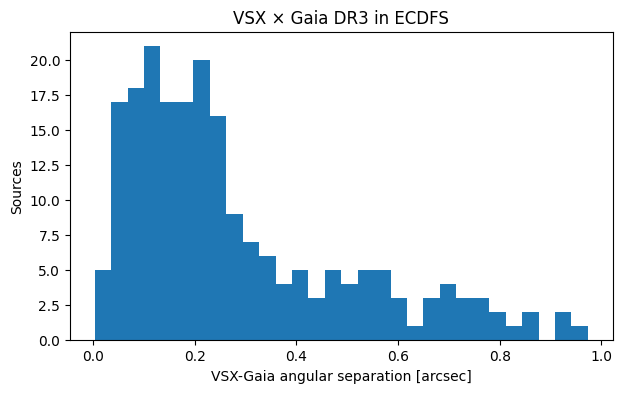

In [ ]:
valid_distance = vsx_gaia_best["vsx_gaia_dist_arcsec"].dropna()
plt.figure(figsize=(7, 4))
plt.hist(valid_distance, bins=30)
plt.xlabel("VSX-Gaia angular separation [arcsec]")
plt.ylabel("Sources")
plt.title(f"VSX × Gaia DR3 in {FIELD}")
plt.show()


## 9. Crossmatch VSX with Rubin alerts

In [ ]:
try:
    vsx_alert_catalog = vsx.crossmatch(
        alerts,
        radius_arcsec=MATCH_RADIUS_ARCSEC,
        n_neighbors=None,
        how="left",
        suffixes=("_vsx", "_alert"),
    )
except (TypeError, ValueError):
    warnings.warn("Using n_neighbors=20 because this LSDB version rejected None.")
    vsx_alert_catalog = vsx.crossmatch(
        alerts,
        radius_arcsec=MATCH_RADIUS_ARCSEC,
        n_neighbors=20,
        how="left",
        suffixes=("_vsx", "_alert"),
    )

vsx_alert_rows = vsx_alert_catalog.compute()
print(vsx_alert_rows.shape)
print(vsx_alert_rows.columns.tolist())
display(vsx_alert_rows.head())


/usr/local/lib/python3.13/dist-packages/lsdb/catalog/catalog.py:410: FutureWarning: The default suffix behavior will change from applying suffixes to all columns to only applying suffixes to overlapping columns in a future release.To maintain the current behavior, explicitly set `suffix_method='all_columns'`. To change to the new behavior, set `suffix_method='overlapping_columns'`.
  warnings.warn(


Computing Catalog:   0%|          | 0/1 [00:00<?, ?it/s]

(221, 18)
['OID_vsx', 'Name_vsx', 'VarFlag_vsx', 'RAdeg_vsx', 'DEdeg_vsx', 'Type_vsx', 'MagMax_vsx', 'MaxPassband_vsx', 'MagMin_vsx', 'MinPassband_vsx', 'Epoch_vsx', 'Period_vsx', 'SpectralType_vsx', 'diaSourceId_alert', 'ra_alert', 'dec_alert', 'prvDiaForcedSources_alert', '_dist_arcsec']


OID_vsx                      Name_vsx  VarFlag_vsx  \
_healpix_29                                                               
2528478682352289901  2894689  Gaia DR3 5056957338272473856            0   
2528558058662877015  2900425  Gaia DR3 5057116118919536896            0   
2528624116322247971  2903557  Gaia DR3 5057248232113756672            0   
2528628914604300395  2904447  Gaia DR3 5057257818480735616            0   
2528634489801291617  2896659  Gaia DR3 5057268951036041216            0   

                     RAdeg_vsx  DEdeg_vsx Type_vsx  MagMax_vsx  \
_healpix_29                                                      
2528478682352289901   52.30729  -28.90523      ROT       18.05   
2528558058662877015   53.32064  -28.85006    E+ROT       16.36   
2528624116322247971   53.87428  -28.30754       RS       15.76   
2528628914604300395    54.0226  -28.11984      ROT       15.65   
2528634489801291617   52.65889   -29.0492        E        16.8   

                    MaxPassband_vsx  MagMin_vsx MinPassband_vsx  Epoch_vsx  \
_healpix_29                                                                  
2528478682352289901               G       18.17               G       <NA>   
2528558058662877015               G       17.28               G       <NA>   
2528624116322247971               G       15.88               G       <NA>   
2528628914604300395               G        15.7               G       <NA>   
2528634489801291617               G       17.18               G       <NA>   

                     Period_vsx SpectralType_vsx   diaSourceId_alert  \
_healpix_29                                                            
2528478682352289901        <NA>             <NA>  170107646612865083   
2528558058662877015     3.80407                K  170107646470258724   
2528624116322247971        <NA>                K  170107646066032646   
2528628914604300395        <NA>                M  170107646066032670   
2528634489801291617      1.2245                K  170107646474453026   

                      ra_alert  dec_alert  \
_healpix_29                                 
2528478682352289901  52.307548 -28.905226   
2528558058662877015  53.320688 -28.850077   
2528624116322247971  53.874216 -28.307479   
2528628914604300395   54.02273 -28.119929   
2528634489801291617   52.65891 -29.049252   

                                             prvDiaForcedSources_alert  \
_healpix_29                                                              
2528478682352289901                                                 []   
2528558058662877015                                                 []   
2528624116322247971                                                 []   
2528628914604300395                                                 []   
2528634489801291617  [{diaForcedSourceId: 170107646474453057, diaOb...   

                     _dist_arcsec  
_healpix_29                        
2528478682352289901      0.812502  
2528558058662877015      0.163635  
2528624116322247971       0.30071  
2528628914604300395      0.523705  
2528634489801291617      0.198697

### Normalize Rubin crossmatch identifiers

In [ ]:
ALERT_OID_RAW = first_existing(vsx_alert_rows.columns, ["OID", "OID_vsx"], contains="OID")
ALERT_DIST_RAW = first_existing(vsx_alert_rows.columns, ["_dist_arcsec"], contains="dist_arcsec")
ALERT_ID_RAW = first_existing(vsx_alert_rows.columns, ["diaSourceId", "diaSourceId_alert"], contains="diaSourceId")

alert_rename = {
    ALERT_OID_RAW: "vsx_oid",
    ALERT_DIST_RAW: "vsx_rubin_dist_arcsec",
    ALERT_ID_RAW: "rubin_diaSourceId",
}
for target, candidates in {
    "vsx_name": ["Name", "Name_vsx"],
    "vsx_type": ["Type", "Type_vsx"],
    "vsx_period": ["Period", "Period_vsx"],
}.items():
    raw = first_existing(vsx_alert_rows.columns, candidates)
    if raw is not None:
        alert_rename[raw] = target

vsx_alert_rows = vsx_alert_rows.rename(columns=alert_rename)
print("Renamed columns:", alert_rename)


Renamed columns: {'OID_vsx': 'vsx_oid', '_dist_arcsec': 'vsx_rubin_dist_arcsec', 'diaSourceId_alert': 'rubin_diaSourceId', 'Name_vsx': 'vsx_name', 'Type_vsx': 'vsx_type', 'Period_vsx': 'vsx_period'}


In [ ]:
vsx_alert_summary = (
    vsx_alert_rows.groupby("vsx_oid", dropna=False)
    .agg(
        vsx_name=("vsx_name", "first"),
        vsx_type=("vsx_type", "first"),
        vsx_period=("vsx_period", "first"),
        n_alert_rows=("rubin_diaSourceId", "count"),
        min_sep_arcsec=("vsx_rubin_dist_arcsec", "min"),
        median_sep_arcsec=("vsx_rubin_dist_arcsec", "median"),
    )
    .reset_index()
)
display(vsx_alert_summary.sort_values("n_alert_rows", ascending=False).head(30))
safe_to_parquet(vsx_alert_rows, "vsx_rubin_alert_rows.parquet")
safe_to_parquet(vsx_alert_summary, "vsx_rubin_summary.parquet")


,vsx_oid,vsx_name,vsx_type,vsx_period,n_alert_rows,min_sep_arcsec,median_sep_arcsec
1,178931,GUVV-2 J033339.3-281723.6,VAR,<NA>,1,0.995865,0.995865
4,252837,SSS 110224:033350-282244,UGSU,<NA>,1,0.031924,0.031924
5,480336,SSS_J032827.8-273339,EW,0.251507,1,0.984981,0.984981
7,480394,SSS_J033551.6-275418,EB|EW,0.572112,1,0.074744,0.074744
16,2893018,Gaia DR3 5059981819882316544,ROT,0.92697,1,0.222151,0.222151
26,2893551,Gaia DR3 5060384245435057920,ROT,0.53741,1,0.152115,0.152115
34,2894175,Gaia DR3 5057355915533748096,ROT,<NA>,1,0.27919,0.27919
40,2894351,Gaia DR3 5060397817531750912,ROT,<NA>,1,0.117095,0.117095
43,2894536,Gaia DR3 5057349558982202880,ROT,<NA>,1,0.993995,0.993995
44,2894689,Gaia DR3 5056957338272473856,ROT,<NA>,1,0.812502,0.812502


Saved: vsx_rubin_alert_rows.parquet
Saved: vsx_rubin_summary.parquet


## 10. Select and flatten Rubin forced-source histories

`prvDiaForcedSources` is selected explicitly whenever it exists. The conversion helper supports DataFrames, Arrow-like objects, record arrays, lists of dictionaries, and nested-pandas values.


In [ ]:
nested_candidates = [
    c for c in vsx_alert_rows.columns
    if "prv" in str(c).lower() or "forced" in str(c).lower()
]

if "prvDiaForcedSources" in nested_candidates:
    NESTED_COLUMN = "prvDiaForcedSources"
elif "prvDiaForcedSources_alert" in nested_candidates:
    NESTED_COLUMN = "prvDiaForcedSources_alert"
elif "prvDiaSources" in nested_candidates:
    NESTED_COLUMN = "prvDiaSources"
elif nested_candidates:
    NESTED_COLUMN = nested_candidates[0]
else:
    NESTED_COLUMN = None

print("Nested candidates:", nested_candidates)
print("Selected history column:", NESTED_COLUMN)


Nested candidates: ['prvDiaForcedSources_alert']
Selected history column: prvDiaForcedSources_alert


In [ ]:
def nested_value_to_dataframe(value):
    if value is None:
        return pd.DataFrame()
    if isinstance(value, pd.DataFrame):
        return pd.DataFrame(value).copy()
    for method in ("to_pandas", "to_pylist", "tolist"):
        if hasattr(value, method):
            try:
                converted = getattr(value, method)()
                return converted.copy() if isinstance(converted, pd.DataFrame) else pd.DataFrame(converted)
            except Exception:
                pass
    try:
        return pd.DataFrame(value)
    except Exception:
        return pd.DataFrame()


def flatten_nested_history(frame, nested_column):
    if nested_column is None:
        return pd.DataFrame()
    pieces = []
    context = [
        c for c in [
            "vsx_oid", "vsx_name", "vsx_type", "vsx_period", "rubin_diaSourceId"
        ] if c in frame.columns
    ]
    for _, row in frame.iterrows():
        nested = nested_value_to_dataframe(row.get(nested_column))
        if nested.empty:
            continue
        for column in context:
            nested[column] = row[column]
        pieces.append(nested)
    return pd.concat(pieces, ignore_index=True) if pieces else pd.DataFrame()

lightcurve_rows = flatten_nested_history(vsx_alert_rows, NESTED_COLUMN)
print("Flattened shape:", lightcurve_rows.shape)
print("Flattened columns:", lightcurve_rows.columns.tolist())
display(lightcurve_rows.head())


Flattened shape: (41, 19)
Flattened columns: ['diaForcedSourceId', 'diaObjectId', 'ra', 'dec', 'visit', 'detector', 'psfFlux', 'psfFluxErr', 'midpointMjdTai', 'scienceFlux', 'scienceFluxErr', 'band', 'timeProcessedMjdTai', 'timeWithdrawnMjdTai', 'vsx_oid', 'vsx_name', 'vsx_type', 'vsx_period', 'rubin_diaSourceId']


,diaForcedSourceId,diaObjectId,ra,dec,visit,detector,psfFlux,psfFluxErr,midpointMjdTai,scienceFlux,scienceFluxErr,band,timeProcessedMjdTai,timeWithdrawnMjdTai,vsx_oid,vsx_name,vsx_type,vsx_period,rubin_diaSourceId
0,170107646474453057,170107645939679274,52.658903,-29.049262,2026030800026,54,-2.321490e+05,4505.822754,61108.032716,1.400787e+06,4532.916016,z,61108.034394,NaN,2896659,Gaia DR3 5057268951036041216,E,1.2245,170107646474453026
1,170107645935484946,170103252049723409,53.104624,-28.809223,2026030800022,50,1.296895e+05,2776.086670,61108.027902,2.218891e+06,2787.201904,r,61108.029861,NaN,2899187,Gaia DR3 5057299668642117376,VAR,0.019117,170107645935484935
2,170019696141664325,313695088049913911,53.457386,-28.378711,2026021600105,43,1.542179e+06,1249.212524,61088.097446,2.077977e+06,1206.613037,r,61088.099298,NaN,252837,SSS 110224:033350-282244,UGSU,<NA>,170103251916029997
3,170068070000230477,313695088049913911,53.457384,-28.378711,2026022700070,128,-2.788646e+04,543.293091,61099.042416,2.204459e+05,540.032898,i,61099.044281,NaN,252837,SSS 110224:033350-282244,UGSU,<NA>,170103251916029997
4,170068070114000977,313695088049913911,53.457388,-28.378714,2026022700071,89,-2.346795e+04,565.336609,61099.043207,2.286847e+05,564.617249,i,61099.045144,NaN,252837,SSS 110224:033350-282244,UGSU,<NA>,170103251916029997


## 11. Identify the Rubin time-series schema explicitly

In [ ]:
EXPECTED = {
    "time": ["midpointMjdTai", "midpointMjd", "mjd", "time"],
    "band": ["band", "filter", "filterName"],
    "flux": ["psfFlux", "forcedPsfFlux", "diffimFlux", "flux"],
    "error": ["psfFluxErr", "forcedPsfFluxErr", "diffimFluxErr", "fluxErr"],
    "id": ["diaForcedSourceId", "diaSourceId", "sourceId"],
}

TIME_COLUMN = first_existing(lightcurve_rows.columns, EXPECTED["time"])
BAND_COLUMN = first_existing(lightcurve_rows.columns, EXPECTED["band"])
FLUX_COLUMN = first_existing(lightcurve_rows.columns, EXPECTED["flux"])
ERROR_COLUMN = first_existing(lightcurve_rows.columns, EXPECTED["error"])
DETECTION_ID_COLUMN = first_existing(lightcurve_rows.columns, EXPECTED["id"])

print({
    "TIME_COLUMN": TIME_COLUMN,
    "BAND_COLUMN": BAND_COLUMN,
    "FLUX_COLUMN": FLUX_COLUMN,
    "ERROR_COLUMN": ERROR_COLUMN,
    "DETECTION_ID_COLUMN": DETECTION_ID_COLUMN,
})


{'TIME_COLUMN': 'midpointMjdTai', 'BAND_COLUMN': 'band', 'FLUX_COLUMN': 'psfFlux', 'ERROR_COLUMN': 'psfFluxErr', 'DETECTION_ID_COLUMN': 'diaForcedSourceId'}


## 12. Clean, deduplicate, and select a source with enough measurements

In [ ]:
lightcurve_clean = lightcurve_rows.copy()

if TIME_COLUMN is not None:
    lightcurve_clean[TIME_COLUMN] = pd.to_numeric(lightcurve_clean[TIME_COLUMN], errors="coerce")
if FLUX_COLUMN is not None:
    lightcurve_clean[FLUX_COLUMN] = pd.to_numeric(lightcurve_clean[FLUX_COLUMN], errors="coerce")
if ERROR_COLUMN is not None:
    lightcurve_clean[ERROR_COLUMN] = pd.to_numeric(lightcurve_clean[ERROR_COLUMN], errors="coerce")

if TIME_COLUMN is not None and FLUX_COLUMN is not None:
    lightcurve_clean = lightcurve_clean.dropna(subset=[TIME_COLUMN, FLUX_COLUMN]).copy()

if DETECTION_ID_COLUMN is not None and not lightcurve_clean.empty:
    lightcurve_clean = lightcurve_clean.drop_duplicates(DETECTION_ID_COLUMN)
elif not lightcurve_clean.empty:
    subset = [c for c in ["vsx_oid", TIME_COLUMN, BAND_COLUMN] if c is not None]
    lightcurve_clean = lightcurve_clean.drop_duplicates(subset)

print("Clean measurements:", len(lightcurve_clean))

if not lightcurve_clean.empty:
    point_counts = lightcurve_clean.groupby("vsx_oid").size().sort_values(ascending=False)
    display(point_counts.head(20).rename("n_measurements"))
    EXAMPLE_OID = point_counts.index[0]
    example_lc = lightcurve_clean[lightcurve_clean["vsx_oid"] == EXAMPLE_OID].copy()
    example_lc = example_lc.sort_values(TIME_COLUMN)
    print("Selected OID:", EXAMPLE_OID, "points:", len(example_lc))


Clean measurements: 41


vsx_oid
480394     12
2893018    11
252837      8
178931      1
480336      1
2894950     1
2896659     1
2898002     1
2898845     1
2899187     1
2901895     1
2903067     1
2904636     1
Name: n_measurements, dtype: int64

Selected OID: 480394 points: 12


## 13. Plot the forced-source alert history

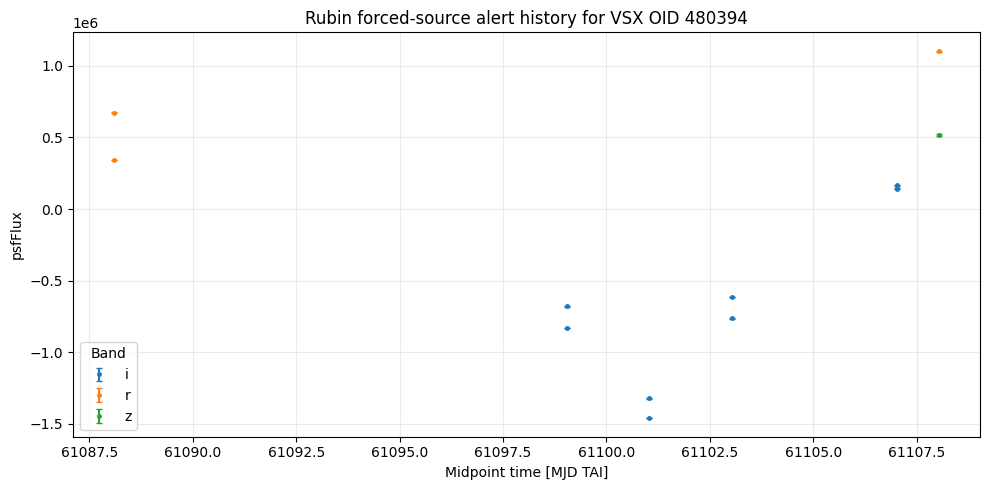

In [ ]:
if (
    not lightcurve_clean.empty
    and TIME_COLUMN is not None
    and FLUX_COLUMN is not None
    and "example_lc" in globals()
):
    fig, ax = plt.subplots(figsize=(10, 5))
    groups = example_lc.groupby(BAND_COLUMN) if BAND_COLUMN is not None else [("all", example_lc)]

    for band, group in groups:
        group = group.sort_values(TIME_COLUMN)
        if ERROR_COLUMN is not None:
            ax.errorbar(
                group[TIME_COLUMN], group[FLUX_COLUMN], yerr=group[ERROR_COLUMN],
                fmt=".", markersize=5, capsize=2, label=str(band)
            )
        else:
            ax.plot(group[TIME_COLUMN], group[FLUX_COLUMN], ".", label=str(band))

    ax.set_xlabel("Midpoint time [MJD TAI]")
    ax.set_ylabel(FLUX_COLUMN)
    ax.set_title(f"Rubin forced-source alert history for VSX OID {EXAMPLE_OID}")
    ax.grid(alpha=0.25)
    ax.legend(title="Band")
    plt.tight_layout()
    plt.show()
else:
    print("No plottable forced-source history was found in this regional sample.")
    print("Selected nested column:", NESTED_COLUMN)
    print("Available flattened columns:", lightcurve_rows.columns.tolist())


## 14. Period validation with Lomb–Scargle

In [ ]:
def lomb_scargle_period(time, value, error=None, minimum_period=0.2, maximum_period=1.0):
    time = np.asarray(time, float)
    value = np.asarray(value, float)
    valid = np.isfinite(time) & np.isfinite(value)
    if error is None:
        model = LombScargle(time[valid], value[valid])
    else:
        error = np.asarray(error, float)
        valid &= np.isfinite(error) & (error > 0)
        model = LombScargle(time[valid], value[valid], error[valid])
    frequency, power = model.autopower(
        minimum_frequency=1.0 / maximum_period,
        maximum_frequency=1.0 / minimum_period,
    )
    return 1.0 / frequency[np.argmax(power)], frequency, power

if "example_lc" in globals() and len(example_lc) >= 8:
    if BAND_COLUMN is not None:
        best_band = example_lc[BAND_COLUMN].value_counts().index[0]
        period_data = example_lc[example_lc[BAND_COLUMN] == best_band]
    else:
        best_band = "all"
        period_data = example_lc

    if len(period_data) >= 8:
        errors = period_data[ERROR_COLUMN] if ERROR_COLUMN is not None else None
        period_ls, frequency, power = lomb_scargle_period(
            period_data[TIME_COLUMN], period_data[FLUX_COLUMN], errors
        )
        print("Best Lomb-Scargle period [days]:", period_ls)


Best Lomb-Scargle period [days]: 0.7139686635130993


# Science branch A: initial anomaly ranking

In [ ]:
gaia_for_merge = vsx_gaia_best[[
    c for c in [
        "vsx_oid", "vsx_gaia_dist_arcsec", "gaia_ruwe", "gaia_parallax",
        "gaia_parallax_error", "gaia_g_mag"
    ] if c in vsx_gaia_best.columns
]].copy()

anomaly_features = vsx_alert_summary.merge(gaia_for_merge, on="vsx_oid", how="left")
anomaly_features["log_n_alert_rows"] = np.log1p(anomaly_features["n_alert_rows"])

numeric_features = [
    c for c in [
        "log_n_alert_rows", "min_sep_arcsec", "median_sep_arcsec",
        "vsx_gaia_dist_arcsec", "gaia_ruwe", "gaia_g_mag"
    ] if c in anomaly_features.columns
]

if len(anomaly_features) >= 10 and numeric_features:
    preprocessing = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", RobustScaler()),
    ])
    X = preprocessing.fit_transform(anomaly_features[numeric_features])
    model = IsolationForest(n_estimators=300, contamination=0.02, random_state=42, n_jobs=-1)
    model.fit(X)
    anomaly_features["anomaly_score"] = -model.score_samples(X)
    anomaly_ranking = anomaly_features.sort_values("anomaly_score", ascending=False)
    display(anomaly_ranking.head(30))
else:
    print("Too few sources for the initial anomaly model.")


,vsx_oid,vsx_name,vsx_type,vsx_period,n_alert_rows,min_sep_arcsec,median_sep_arcsec,vsx_gaia_dist_arcsec,gaia_ruwe,gaia_parallax,gaia_parallax_error,gaia_g_mag,log_n_alert_rows,anomaly_score
1,178931,GUVV-2 J033339.3-281723.6,VAR,<NA>,1,0.995865,0.995865,<NA>,<NA>,<NA>,<NA>,<NA>,0.693147,0.786376
43,2894536,Gaia DR3 5057349558982202880,ROT,<NA>,1,0.993995,0.993995,0.617078,0.979641,1.057941,0.048839,16.70104,0.693147,0.649984
5,480336,SSS_J032827.8-273339,EW,0.251507,1,0.984981,0.984981,0.598897,1.013287,1.205837,0.024846,15.1542,0.693147,0.648529
101,2898024,Gaia DR3 5057375358849199232,ROT,<NA>,1,0.881273,0.881273,0.576604,1.057078,2.082085,0.135602,18.171152,0.693147,0.634503
91,2897751,Gaia DR3 5057395223072711424,ROT,8.2688,0,<NA>,<NA>,0.167391,9.992319,1.237208,0.182076,14.744097,0.0,0.632626
100,2898002,Gaia DR3 5057496614365866368,ROT,<NA>,1,0.774973,0.774973,0.147912,1.010219,1.440762,0.153202,18.626537,0.693147,0.620414
93,2897845,Gaia DR3 5060606209344715264,ROT,3.45283,1,0.371099,0.371099,0.247578,1.64066,1.032254,0.047633,15.498857,0.693147,0.616033
215,8301017,Gaia DR3 5057453664692923136,S,<NA>,0,<NA>,<NA>,0.005677,<NA>,<NA>,<NA>,18.007334,0.0,0.609677
4,252837,SSS 110224:033350-282244,UGSU,<NA>,1,0.031924,0.031924,0.152779,1.020434,1.507151,0.051895,18.052298,0.693147,0.607631
49,2894950,Gaia DR3 5060576385091776896,ROT,1.88233,1,0.668139,0.668139,0.420326,0.968539,2.189207,0.035541,16.0585,0.693147,0.607102


# Science branch B: RR Lyrae distance preparation

In [ ]:
rr_gaia = vsx_gaia_best[
    vsx_gaia_best["vsx_type"].astype("string").str.upper().str.contains(
        RR_PATTERN, regex=True, na=False
    )
].copy()
rr_gaia["period_days"] = pd.to_numeric(rr_gaia["vsx_period"], errors="coerce")
if {"gaia_parallax", "gaia_parallax_error"}.issubset(rr_gaia.columns):
    rr_gaia["parallax_snr"] = rr_gaia["gaia_parallax"] / rr_gaia["gaia_parallax_error"]
display(rr_gaia.head(30))


def absolute_magnitude_plz(period, metallicity, alpha, beta, gamma):
    return alpha + beta * np.log10(period) + gamma * metallicity


def distance_modulus(mean_magnitude, absolute_magnitude, extinction=0.0):
    return mean_magnitude - extinction - absolute_magnitude


def distance_parsec(mu):
    return 10.0 ** ((mu + 5.0) / 5.0)


/tmp/ipykernel_1464/113763610.py:2: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  vsx_gaia_best["vsx_type"].astype("string").str.upper().str.contains(


,vsx_oid,vsx_name,VarFlag_vsx,RAdeg_vsx,DEdeg_vsx,vsx_type,MagMax_vsx,MaxPassband_vsx,MagMin_vsx,MinPassband_vsx,Epoch_vsx,vsx_period,SpectralType_vsx,gaia_source_id,ref_epoch_gaia,ra_gaia,dec_gaia,gaia_parallax,gaia_parallax_error,pmra_gaia,pmra_error_gaia,pmdec_gaia,pmdec_error_gaia,gaia_ruwe,gaia_g_mag,phot_bp_mean_mag_gaia,phot_rp_mean_mag_gaia,vsx_gaia_dist_arcsec,gaia_match_ok,period_days,parallax_snr
_healpix_29,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2540771540180594195,178937,GUVV-2 J033500.4-272854.8,0,53.75187,-27.48197,RRAB,14.68,CV,0.83,CV,2454449.47,0.697574,<NA>,5081543075400797312,2016.0,53.751899,-27.481987,0.14181,0.019826,4.858624,0.012791,-6.86489,0.019779,1.11785,14.553511,14.774092,14.180634,0.110982,True,0.697574,7.152641
2528551671458092321,672397,PS1-3PI J033317.09-290331.4,0,53.32123,-29.05875,RRAB,20.44,r,0.59,r,2457000.584,0.578005,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,False,0.578005,<NA>


## 15. Final checkpoints

In [ ]:
safe_to_parquet(vsx_gaia_best, "vsx_gaia_best.parquet")
safe_to_parquet(vsx_alert_rows, "vsx_rubin_alert_rows.parquet")
safe_to_parquet(vsx_alert_summary, "vsx_rubin_summary.parquet")
if not lightcurve_clean.empty:
    safe_to_parquet(lightcurve_clean, "rubin_alert_history_clean.parquet")
if "anomaly_ranking" in globals():
    safe_to_parquet(anomaly_ranking, "vsx_rubin_anomaly_ranking.parquet")
safe_to_parquet(rr_gaia, "rrlyrae_vsx_gaia_sample.parquet")


Saved: vsx_gaia_best.parquet
Saved: vsx_rubin_alert_rows.parquet
Saved: vsx_rubin_summary.parquet
Saved: rubin_alert_history_clean.parquet
Saved: vsx_rubin_anomaly_ranking.parquet
Saved: rrlyrae_vsx_gaia_sample.parquet


## Scientific limitations

- VSX classifications and periods are heterogeneous.
- A one-arcsecond match is a starting point, not a universal optimum.
- High-proper-motion stars may require epoch propagation.
- Alert histories can repeat previous measurements across packets.
- Forced-source alert fluxes are not automatically equivalent to calibrated total-flux light curves.
- The public archive is a finite sample, not the complete Rubin survey.
